# Differential geometry 1: Curves

*Learning path: differential geometry, part 1 of 7.* [Index](README.md) · Next: [Metrics and coordinates](02-metrics.ipynb)

Differential geometry studies shapes using calculus. Before surfaces and curved spaces we start with the simplest
case: a curve. You will learn

* how to describe a curve with a **parameter**,
* how its **velocity** and **speed** follow from derivatives,
* how to measure its **length**, even when there is no formula for it,
* what the **curvature** of a curve is, and how to compute it.

Every code cell can be edited and re-run. A line ending in `;` is computed without showing its result.

## 1. A curve is a moving point

A curve in the plane is a point $(x(t), y(t))$ that moves as the parameter $t$ changes. Think of $t$ as time. An
ellipse with half-axes $a$ and $b$:

In [1]:
x = a*cos(t)
y = b*sin(t)

a*cos(t)

b*sin(t)

Galileo keeps $a$ and $b$ as symbols. To draw it we pick numbers. `parametric(x, y, t, from, to)` draws the curve:

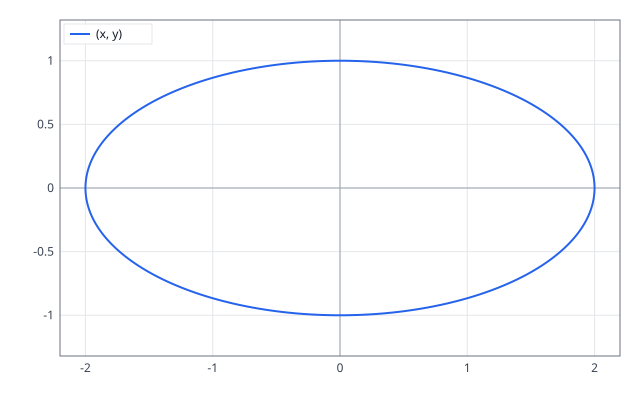

In [2]:
a = 2;
b = 1;
parametric(x, y, t, 0, 2*pi)

## 2. Velocity and speed

The velocity is the derivative of the position: $\big(x'(t), y'(t)\big)$. The speed is its length,
$\sqrt{x'^2 + y'^2}$. We clear the numbers first so that the results stay symbolic.

In [3]:
clear
x = a*cos(t);
y = b*sin(t);
deriv(x, t)
deriv(y, t)
speed = sqrt(deriv(x, t)^2 + deriv(y, t)^2)

-a*sin(t)

b*cos(t)

sqrt(a^2*sin(t)^2+b^2*cos(t)^2)

The point moves fastest at the ends of the short axis and slowest at the ends of the long axis. For a circle
($a = b$) the speed is constant:

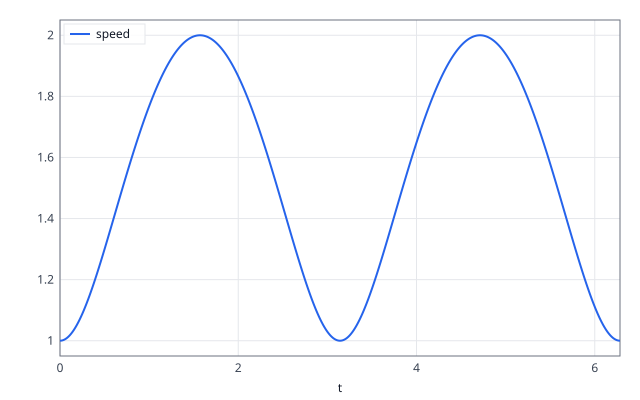

In [4]:
a = 2;
b = 1;
plot(speed, t, 0, 2*pi)

## 3. Length

The length of a curve is the integral of the speed: $L = \int \sqrt{x'^2 + y'^2}\,dt$. For a circle that gives
$2\pi r$, but for an ellipse there is **no formula** in terms of elementary functions. Galileo can still compute it
numerically: `odesolve` solves $dL/dt = \text{speed}$ starting from $L = 0$, which is the same as integrating.

In [5]:
odesolve([speed], [len], t, [0], 0, 2*pi)

9.688448220549146

So the ellipse with half-axes 2 and 1 has circumference about 9.688. Ramanujan's famous approximation
$\pi\,[\,3(a+b) - \sqrt{(3a+b)(a+3b)}\,]$ is remarkably close:

In [6]:
eval(pi*(3*(a+b) - sqrt((3*a+b)*(a+3*b))))

9.688421097671288

## 4. Curvature

How sharply does a curve bend? A straight line does not bend at all; a small circle bends more than a big one. The
**curvature** $\kappa$ of a circle of radius $r$ is $1/r$. For any plane curve,

$$\kappa = \frac{x'y'' - y'x''}{(x'^2 + y'^2)^{3/2}}$$

In [7]:
clear
x = a*cos(t);
y = b*sin(t);
k = simplify((deriv(x, t)*deriv(deriv(y, t), t) - deriv(y, t)*deriv(deriv(x, t), t))/(deriv(x, t)^2 + deriv(y, t)^2)^(3/2))

a*b/(a^2*sin(t)^2+b^2*cos(t)^2)^(3/2)

Check: for a circle, $a = b = r$, the denominator becomes $(r^2)^{3/2} = r^3$ and $\kappa = r^2/r^3 = 1/r$.

For our ellipse the curvature is largest at the ends of the long axis ($t = 0$ and $t = \pi$), where the ellipse is
most pointed:

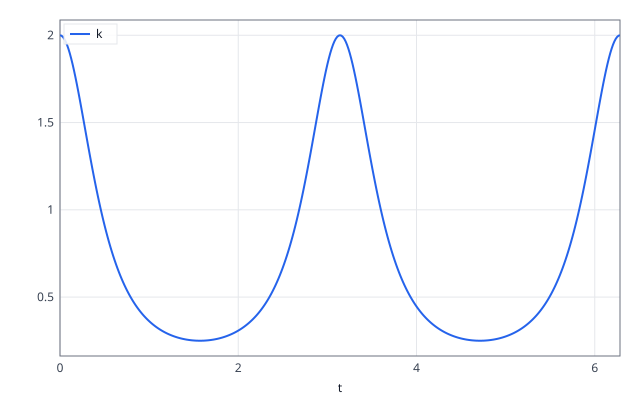

In [8]:
a = 2;
b = 1;
plot(k, t, 0, 2*pi)

### The osculating circle

At each point, the circle that hugs the curve best has radius $1/\kappa$: the *osculating* ("kissing") circle. At
$t = 0$ the ellipse has $\kappa = a/b^2 = 2$, so the kissing circle has radius $1/2$ and its centre is at
$(a - 1/2, 0)$. At $t = \pi/2$, $\kappa = b/a^2 = 1/4$ and the circle has radius 4:

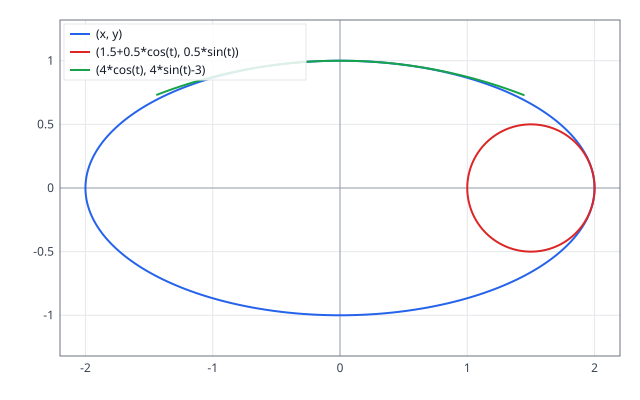

In [9]:
ellipse = parametric(x, y, t, 0, 2*pi);
kiss1 = parametric(1.5 + 0.5*cos(t), 0.5*sin(t), t, 0, 2*pi);
kiss2 = parametric(4*cos(t), 4*sin(t) - 3, t, 1.2, 1.94);
show(ellipse, kiss1, kiss2)

## 5. Curves in space

A curve in space has three components. The helix winds around a cylinder of radius $R$, rising $2\pi c$ per turn:

In [10]:
clear
x = R*cos(t);
y = R*sin(t);
z = c*t;
simplify(deriv(x, t)^2 + deriv(y, t)^2 + deriv(z, t)^2)

R^2+c^2

Its speed is constant, $\sqrt{R^2 + c^2}$. In space the curvature is $\kappa = |r' \times r''| / |r'|^3$. We compute
the cross product component by component:

In [11]:
cx = deriv(y, t)*deriv(deriv(z, t), t) - deriv(z, t)*deriv(deriv(y, t), t);
cy = deriv(z, t)*deriv(deriv(x, t), t) - deriv(x, t)*deriv(deriv(z, t), t);
cz = deriv(x, t)*deriv(deriv(y, t), t) - deriv(y, t)*deriv(deriv(x, t), t);
simplify(cx^2 + cy^2 + cz^2)

R^2*(R^2+c^2)

So $|r' \times r''| = R\sqrt{R^2+c^2}$ and $\kappa = R/(R^2 + c^2)$: a helix has the same curvature everywhere, like
a circle, but it also twists out of the plane (its *torsion* is $c/(R^2+c^2)$). Here is one with $R = 1$,
$c = 0.15$; drag to rotate it:

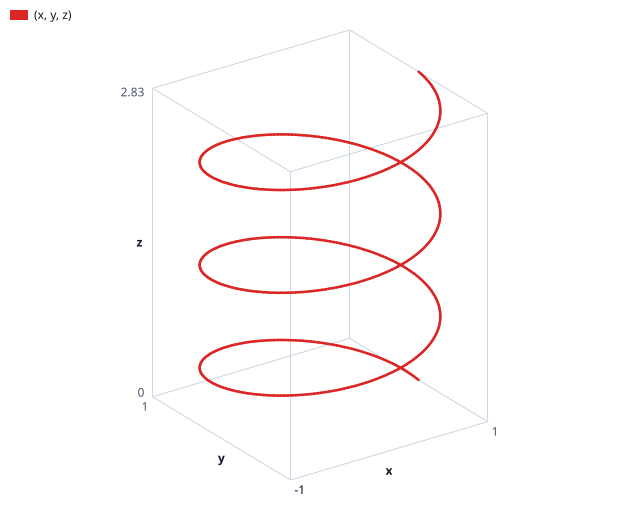

In [12]:
R = 1;
c = 0.15;
parametric3d(x, y, z, t, 0, 6*pi)

## Summary

* A curve is a point that moves with a parameter; its velocity is the derivative and its speed the velocity's length.
* Length is the integral of speed; `odesolve` computes it when there is no formula.
* Curvature measures bending: $1/r$ for a circle, and the osculating circle hugs the curve.

**Try it:** change $a$ and $b$ and re-run the cells. What happens to the curvature plot when $a = b$?

Next: [Metrics and coordinates](02-metrics.ipynb), where we measure lengths inside a space instead of along a curve.